# 线性回归：Stata 实验 {#sec-linear-regression-lab}

[返回理论篇](../../lectures/linear-regression.qmd) · [数据说明](../../data/linear-regression/README.md) · [完整 do-file](../../tools/linear-regression/linear-regression.do)

本实验保留工资、汽车和企业财务案例，核对去均值、FWL、虚拟变量的两种参数化，以及中心化前后的拟合等价性。数据均读取本地快照；网页只展示从头运行后保存的实际结果，不执行代码或实时取数。企业数据来源的部分口径未完整说明，结果只作教学演示。

从仓库根目录运行 `python tools/linear-regression/run_notebook.py`。需要已配置的 `STATA_EXE` 和 nbstata 环境。


In [1]:
%%quietly
local project_root : environment FINECO_ROOT
cd "`project_root'"



Running D:\stata19/profile.do ...
file D:/stata/do/log-14Oct2026-16-42-24.log could not be opened
r(603);



## 运行准备

校验冻结数据并检查 SSC 命令；已安装的命令不会重复安装。

In [2]:
* 线性回归：估计、FWL、虚拟变量与交乘项。
* 从 FinEco 仓库根目录运行；数据为本地冻结快照。
* 图形导出到 figs/raw，机器核对值保存至 logs/linear-regression。
* 二维聚类的缺失标准误与警告保留为少簇推断边界演示。

capture mkdir "logs"
capture mkdir "logs/linear-regression"
capture mkdir "figs"
capture mkdir "figs/raw"
clear all
set more off
* 数据全部读取本地冻结快照；从 FinEco 仓库根目录执行。
global D "data/linear-regression"
* 所需 SSC 命令；用户已授权安装，已有命令不重复安装。
foreach cmd in estout binscatter ftools reghdfe {
    capture which `cmd'
    if _rc {
        ssc install `cmd', replace
    }
}
*===========================================================================


## 案例情境：一个系数，三种读法

按顺序运行，比较同一段中不同设定的输出。

In [3]:

*===========================================================================

use "$D/mroz.dta", clear
* 只保留在职女性(wage>0)、剔除个别极端高薪，并把人数过少的教育年限并组
drop if wage==0
drop if wage>17
replace educ = 9  if educ<=9
replace educ = 14 if educ==15
reg wage educ
assert e(N) == 421
file open check using "logs/linear-regression/results.txt", write replace
file write check "mroz_N=" (e(N)) _n "mroz_b=" (_b[educ]) _n
* wage = -2.74 + 0.52*educ：0.52 该读成"因果/比较/预测"中的哪一种？


*===========================================================================


(325 observations deleted)
(7 observations deleted)
(18 real changes made)
(6 real changes made)

      Source |       SS           df       MS      Number of obs   =       421
-------------+----------------------------------   F(1, 419)       =    115.85
       Model |  516.105831         1  516.105831   Prob > F        =    0.0000
    Residual |    1866.698       419   4.4551265   R-squared       =    0.2166
-------------+----------------------------------   Adj R-squared   =    0.2147
       Total |  2382.80383       420  5.67334246   Root MSE        =    2.1107



------------------------------------------------------------------------------


        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]


-------------+----------------------------------------------------------------


        educ |

      0.522      0.048    10.76   0.000        0.426       0.617
       _cons |     -2.744      0.624    -4.40   0.000       -3.971      -1.517


------------------------------------------------------------------------------


## 概念讲解：回归到底在估计什么

按顺序运行，比较同一段中不同设定的输出。


    educ   wage_m  
       9      2.5  
      10      3.2  
      11      2.6  
      12      3.4  
      13      3.9  
      14      4.1  
      16      4.7  
      17      7.4  

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
        wage |        208    3.433929    1.759613      .1616     11.933
------------------------------------------------------------------------------
        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
       _cons |      3.434      0.122    28.15   0.000        3.193       3.674
------------------------------------------------------------------------------


file figs/raw/linear-reg-fig01-cef-edu-20261014-163740.png written in PNG forma
> t

      Source |       SS           df       MS      Number of obs   =       421
-------------+----------------------------------   F(1, 419)       =    115.85
       Model |  516.105831         1  516.105831   Prob > F        =    0.0000
    Residual |    1866.698       419   4.4551265   R-squared       =    0.2166
-------------+----------------------------------   Adj R-squared   =    0.2147
       Total |  2382.80383       420  5.67334246   Root MSE        =    2.1107

------------------------------------------------------------------------------
        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
        educ |      0.522      0.048    10.76   0.000        0.426       0.617
       _cons |     -2.744      0.624    -4.40   0.000       -3.971      -1.517
---------------------------------------------


      Source |       SS           df       MS      Number of obs   =         8
-------------+----------------------------------   F(1, 6)         =     23.55
       Model |  13.7292056         1  13.7292056   Prob > F        =    0.0028
    Residual |   3.4975139         6  .582918983   R-squared       =    0.7970
-------------+----------------------------------   Adj R-squared   =    0.7631
       Total |  17.2267195         7  2.46095993   Root MSE        =    .76349

------------------------------------------------------------------------------
      wage_m | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
        educ |      0.497      0.102     4.85   0.003        0.247       0.748
       _cons |     -2.361      1.334    -1.77   0.127       -5.626       0.904
------------------------------------------------------------------------------
(sum of wgt is 421)



      Source |       SS           df       MS      Number of obs   =         8
-------------+----------------------------------   F(1, 6)         =     25.47
       Model |   9.8072367         1   9.8072367   Prob > F        =    0.0023
    Residual |  2.31064314         6   .38510719   R-squared       =    0.8093
-------------+----------------------------------   Adj R-squared   =    0.7775
       Total |  12.1178798         7  1.73112569   Root MSE        =    .62057

------------------------------------------------------------------------------
      wage_m | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
        educ |      0.522      0.103     5.05   0.002        0.269       0.774
       _cons |     -2.744      1.331    -2.06   0.085       -6.001       0.514
------------------------------------------------------------------------------



------------------------------------------------------------
                      (1)             (2)             (3)   
               individual       groupmean    groupmean_aw   
------------------------------------------------------------
educ                0.522***        0.497**         0.522** 
                  (0.048)         (0.102)         (0.103)   
_cons              -2.744***       -2.361          -2.744   
                  (0.624)         (1.334)         (1.331)   
------------------------------------------------------------
N                     421               8               8   
r2                  0.217           0.797           0.809   
------------------------------------------------------------
Standard errors in parentheses
* p<0.05, ** p<0.01, *** p<0.001


...

------------------------------------------------------------------------------
      tenure | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
     ttl_exp |      0.687      0.021    32.52   0.000        0.645       0.728
       grade |      0.020      0.039     0.52   0.606       -0.056       0.095
       _cons |     -2.911      0.531    -5.49   0.000       -3.951      -1.871
------------------------------------------------------------------------------
(17 missing values generated)

      Source |       SS           df       MS      Number of obs   =     2,229
-------------+----------------------------------   F(1, 2228)      =      2.28
       Model |  64.4869925         1  64.4869925   Prob > F        =    0.1315
    Residual |  63124.2663     2,228   28.332256   R-squared       =    0.0010
-------------+----------------------------------   Adj R-squared   =    0.0006
       Total |  63188

------------------------------------------------------------------------------
      wage_r | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
    tenure_r |      0.038      0.025     1.51   0.132       -0.011       0.087
------------------------------------------------------------------------------

      Source |       SS           df       MS      Number of obs   =     2,229
-------------+----------------------------------   F(1, 2227)      =      1.52
       Model |  43.0583016         1  43.0583016   Prob > F        =    0.2180
    Residual |   63145.695     2,227  28.3546004   R-squared       =    0.0007
-------------+----------------------------------   Adj R-squared   =    0.0002
       Total |  63188.7533     2,228  28.3611999   Root MSE        =    5.3249



------------------------------------------------------------------------------
      wage_r | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
      tenure |      0.025      0.020     1.23   0.218       -0.015       0.065
       _cons |     -0.151      0.166    -0.91   0.365       -0.477       0.176
------------------------------------------------------------------------------

      Source |       SS           df       MS      Number of obs   =     2,229
-------------+----------------------------------   F(1, 2227)      =     73.12
       Model |  2355.32774         1  2355.32774   Prob > F        =    0.0000
    Residual |    71732.64     2,227  32.2104356   R-squared       =    0.0318
-------------+----------------------------------   Adj R-squared   =    0.0314
       Total |  74087.9678     2,228  33.2531274   Root MSE        =    5.6754



------------------------------------------------------------------------------
        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
      tenure |      0.187      0.022     8.55   0.000        0.144       0.230
       _cons |      6.680      0.177    37.67   0.000        6.332       7.027
------------------------------------------------------------------------------
(17 missing values generated)
(17 missing values generated)



      Source |       SS           df       MS      Number of obs   =     2,229
-------------+----------------------------------   F(1, 2228)      =     73.16
       Model |  2355.32774         1  2355.32774   Prob > F        =    0.0000
    Residual |    71732.64     2,228  32.1959785   R-squared       =    0.0318
-------------+----------------------------------   Adj R-squared   =    0.0314
       Total |  74087.9678     2,229   33.238209   Root MSE        =    5.6742

------------------------------------------------------------------------------
     wage_dm | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
   tenure_dm |      0.187      0.022     8.55   0.000        0.144       0.230
------------------------------------------------------------------------------


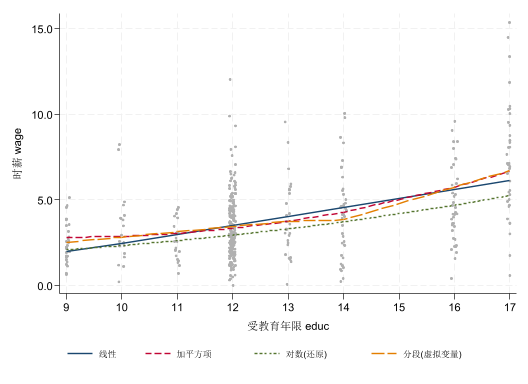

In [4]:

*===========================================================================

**## 条件期望函数 (CEF)：按 X 分组求平均
bysort educ: egen wage_m = mean(wage)   // E(wage | educ)
egen tag = tag(educ)
format wage* %3.1f
list educ wage_m if tag==1, clean noobs

* 某一组的 CEF = 条件均值（下面两条等价）
sum wage if educ==12
reg wage if educ==12, noheader

* CEF 散点图（灰点=个体，菱形=各组均值，红线=OLS 拟合）
twoway (scatter wage educ, mcolor(gs10) msize(vsmall) jitter(2)) ///
(scatter wage_m educ if tag==1, mcolor(navy) msize(medlarge) ///
    msymbol(D)) ///
       (lfit wage educ, lcolor(cranberry) lwidth(medthick)), ///
       legend(order(2 "各教育年限的平均工资 E[wage|educ]" 3 "OLS 拟合直线") ///
              rows(2) size(small) pos(11) ring(0)) ///
       xtitle("受教育年限 educ") ytitle("时薪 wage") xlabel(9(1)17)
graph export "figs/raw/linear-reg-fig01-cef-edu-20261014-163740.png" , ///
    replace width(1200)

**## 回归估计的就是 CEF（个体 = 分组均值加权回归）
bysort educ: egen Nj = count(educ)
eststo clear
eststo m1: reg wage   educ                       // 个体回归
eststo m2: reg wage_m educ if tag==1             // 只用 8 个组均值
eststo m3: reg wage_m educ if tag==1 [aweight=Nj] // 组均值，按组容量加权
esttab m1 m2 m3, nogap mtitle(individual groupmean groupmean_aw) ///
       b(%5.3f) se(%5.3f) scalar(N r2)
* 第 (1)(3) 列点估计相同；组均值是总体 CEF 的样本估计

**## 线性投影 & 换一个 f(.) 就是换一个模型
gen educ2 = educ^2
eststo clear
eststo s1: reg wage  educ             // (1) 线性
eststo s2: reg wage  educ educ2       // (2) 平方项：允许弯曲
eststo s3: reg lwage educ             // (3) 对数：改变尺度
esttab s1 s2 s3, nogap mtitle(linear quad log) b(%5.3f) se(%5.3f) ///
    scalar(N r2)

* 四种设定的拟合线画在同一张散点图上
reg wage educ
predict yhat_lin
reg wage educ c.educ#c.educ
predict yhat_quad
reg lwage educ
predict lyhat
gen yhat_log = exp(lyhat)  // 指数还原，不是条件均值
gen Dhi = (educ>13)
reg wage c.educ##i.Dhi
predict yhat_dum
sort educ
twoway (scatter wage educ, mcolor(gs11) msize(vsmall) jitter(2)) ///
       (line yhat_lin  educ, lcolor(navy)      lwidth(medthick)) ///
(line yhat_quad educ, lcolor(cranberry) lwidth(medthick) ///
    lpattern(dash)) ///
(line yhat_log educ, lcolor(forest_green) lwidth(medthick) ///
    lpattern(shortdash)) ///
(line yhat_dum educ, lcolor(dkorange) lwidth(medthick) ///
    lpattern(longdash)), ///
       legend(order(2 "线性" 3 "加平方项" 4 "对数(还原)" 5 "分段(虚拟变量)") ///
              rows(1) size(small) pos(6)) ///
       xtitle("受教育年限 educ") ytitle("时薪 wage") xlabel(9(1)17)
graph export ///
    "figs/raw/linear-reg-fig02-four-models-20261014-163740.png" , ///
    replace width(1300)

**## 2.5–2.7 系数含义、比较 vs 影响、多元回归偏效应
* 更明显的偏效应例子：nlsw88 中 tenure(任职年限) 在控制 ttl_exp(总工龄) 后骤降
sysuse nlsw88, clear
eststo clear
eststo n1: reg wage tenure
eststo n2: reg wage tenure ttl_exp
eststo n3: reg wage tenure ttl_exp grade
esttab n1 n2 n3, se star(* 0.10 ** 0.05 *** 0.01) r2 ///
       mtitle("只放 tenure" "+总工龄" "+受教育")
* tenure 0.186*** → 0.041(不显著)：控制总工龄后，"纯任职"效应很小
corr tenure ttl_exp

**## 常数项与 FWL：同一样本核对
reg wage tenure ttl_exp grade
gen byte sample_fwl = e(sample)
scalar b_full = _b[tenure]
file write check "tenure_full=" (b_full) _n
reg wage ttl_exp grade if sample_fwl
predict double wage_r if sample_fwl, residuals
reg tenure ttl_exp grade if sample_fwl
predict double tenure_r if sample_fwl, residuals
reg wage_r tenure_r if sample_fwl, noconstant
scalar fwl_gap = _b[tenure_r]-b_full
assert abs(fwl_gap) < 1e-10
file write check "fwl_gap=" (fwl_gap) _n
* 只处理 y 的反例。
reg wage_r tenure if sample_fwl
file write check "y_only_b=" (_b[tenure]) _n
* 单变量回归去均值的核对。
reg wage tenure if sample_fwl
scalar b_simple = _b[tenure]
quietly summarize wage if sample_fwl
gen double wage_dm = wage-r(mean) if sample_fwl
quietly summarize tenure if sample_fwl
gen double tenure_dm = tenure-r(mean) if sample_fwl
reg wage_dm tenure_dm if sample_fwl, noconstant
assert abs(_b[tenure_dm]-b_simple) < 1e-10
file write check "demean_gap=" (_b[tenure_dm]-b_simple) _n


*===========================================================================


## 代码实操

按顺序运行，比较同一段中不同设定的输出。

(332 observations deleted)
(18 real changes made)
(6 real changes made)

      Source |       SS           df       MS      Number of obs   =       421
-------------+----------------------------------   F(1, 419)       =    115.85
       Model |  516.105831         1  516.105831   Prob > F        =    0.0000
    Residual |    1866.698       419   4.4551265   R-squared       =    0.2166
-------------+----------------------------------   Adj R-squared   =    0.2147
       Total |  2382.80383       420  5.67334246   Root MSE        =    2.1107

------------------------------------------------------------------------------
        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
        educ |      0.522      0.048    10.76   0.000        0.426       0.617
       _cons |     -2.744      0.624    -4.40   0.000       -3.971      -1.517
---------------------------------------------------------


         wage    wage_hat        e_hat  
  1.    3.354   3.5144481   -.16044802  
  2.   1.3889   3.5144481   -2.1255481  
  3.   4.5455   3.5144481    1.0310517  

      Source |       SS           df       MS      Number of obs   =       421
-------------+----------------------------------   F(1, 419)       =    115.85
       Model |  516.105831         1  516.105831   Prob > F        =    0.0000
    Residual |    1866.698       419   4.4551265   R-squared       =    0.2166
-------------+----------------------------------   Adj R-squared   =    0.2147
       Total |  2382.80383       420  5.67334246   Root MSE        =    2.1107

------------------------------------------------------------------------------
        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
        educ |      0.522      0.048    10.76   0.000        0.426       0.617
       _cons |     -2.744      0.624    -4.


      Source |       SS           df       MS      Number of obs   =       421
-------------+----------------------------------   F(2, 418)       =     68.40
       Model |  587.526847         2  293.763424   Prob > F        =    0.0000
    Residual |  1795.27699       418  4.29492102   R-squared       =    0.2466
-------------+----------------------------------   Adj R-squared   =    0.2430
       Total |  2382.80383       420  5.67334246   Root MSE        =    2.0724

------------------------------------------------------------------------------
        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
        educ |      0.524      0.048    11.01   0.000        0.431       0.618
       exper |      0.051      0.013     4.08   0.000        0.026       0.076
       _cons |     -3.448      0.637    -5.42   0.000       -4.699      -2.196
--------------------------------------------------


--------------------------------------------
                      (1)             (2)   
                    模型1           模型2   
--------------------------------------------
educ                0.522***        0.524***
                 (0.0485)        (0.0476)   

exper                              0.0512***
                                 (0.0125)   

_cons              -2.744***       -3.448***
                  (0.624)         (0.637)   
--------------------------------------------
N                     421             421   
R-sq                0.217           0.247   
--------------------------------------------
Standard errors in parentheses
* p<0.10, ** p<0.05, *** p<0.01

      Source |       SS           df       MS      Number of obs   =       421
-------------+----------------------------------   F(1, 419)       =    115.85
       Model |  516.105831         1  516.105831   Prob > F        =    0.0000
    Residual |    1866.698       419   4.4551265   R-squared       =  

------------------------------------------------------------------------------
        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
        educ |      0.522      0.048    10.76   0.000        0.426       0.617
       _cons |     -2.744      0.624    -4.40   0.000       -3.971      -1.517
------------------------------------------------------------------------------

      Source |       SS           df       MS      Number of obs   =       421
-------------+----------------------------------   F(1, 419)       =    115.85
       Model |  5161058.31         1  5161058.31   Prob > F        =    0.0000
    Residual |    18666980       419   44551.265   R-squared       =    0.2166
-------------+----------------------------------   Adj R-squared   =    0.2147
       Total |  23828038.3       420  56733.4246   Root MSE        =    211.07



...


Linear regression                               Number of obs     =      1,861
                                                F(4, 11)          =     697.30
                                                Prob > F          =     0.0000
                                                R-squared         =     0.2524
                                                Root MSE          =     3.6107

                              (Std. err. adjusted for 12 clusters in industry)
------------------------------------------------------------------------------
             |               Robust
        wage | Coefficient  std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
         age |     -0.054      0.035    -1.54   0.151       -0.131       0.023
     ttl_exp |      0.297      0.024    12.57   0.000        0.245       0.349
       union |      0.975      0.413     2.36   0.038        0.066       1.885
    collgrad |

(MWFE estimator converged in 1 iterations)


> lbach & Miller applied.

HDFE Linear regression                            Number of obs   =      1,861
Absorbing 1 HDFE group                            F(   4,     11) =    1092.14
Statistics robust to heteroskedasticity           Prob > F        =     0.0000
                                                  R-squared       =     0.2524
                                                  Adj R-squared   =     0.2508
Number of clusters (industry) =         12        Within R-sq.    =     0.2524
Number of clusters (occupation) =         13      Root MSE        =     3.6107



                   (Std. err. adjusted for 12 clusters in industry occupation)
------------------------------------------------------------------------------
             |               Robust
        wage | Coefficient  std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
         age |     -0.054          .        .       .            .           .
     ttl_exp |      0.297          .        .       .            .           .
       union |      0.975          .        .       .            .           .
    collgrad |      3.140          .        .       .            .           .
       _cons |      4.858          .        .       .            .           .
------------------------------------------------------------------------------


----------------------------------------------------------------------------
                      (1)             (2)             (3)             (4)   
                      OLS          Robust           Clus1           Clus2   
----------------------------------------------------------------------------
age                -0.054*         -0.054**        -0.054          -0.054   
                 (0.0278)        (0.0271)        (0.0349)             (.)   
ttl_exp             0.297***        0.297***        0.297***        0.297   
                 (0.0185)        (0.0172)        (0.0236)             (.)   
union               0.975***        0.975***        0.975**         0.975   
                 (0.1954)        (0.2065)        (0.4133)             (.)   
collgrad            3.140***        3.140***        3.140***        3.140   
                 (0.1959)        (0.2407)        (0.3934)             (.)   
----------------------------------------------------------------------------

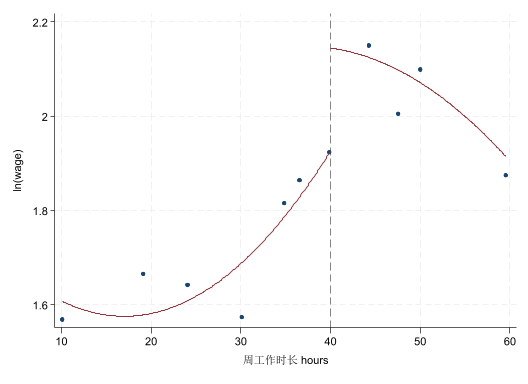

In [5]:

*===========================================================================

**## 跑第一个回归：从命令到拟合值
use "$D/mroz.dta", clear
drop if wage==0 | wage>17
replace educ = 9 if educ<=9
replace educ = 14 if educ==15
reg wage educ
predict wage_hat            // 拟合值
predict e_hat, residual     // 残差
list wage wage_hat e_hat in 1/3, clean

**## 读懂一张回归表（esttab）
eststo clear
eststo t1: reg wage educ
eststo t2: reg wage educ exper
esttab t1 t2, se star(* 0.10 ** 0.05 *** 0.01) r2 mtitle("模型1" "模型2")

**## 换个单位，系数会变吗：变量的尺度
gen wage_cents  = wage*100
gen educ_months = educ*12
eststo clear
eststo a0: reg wage       educ
eststo a1: reg wage_cents educ
eststo a2: reg wage       educ_months
esttab a0 a1 a2, nogap mtitle(wage wage_cents educ_months) ///
       b(%7.4f) se(%7.4f) scalar(r2)

**## 对数与标准化：系数怎么读
* 3.4a 对数-水平：半弹性（%）
reg lwage educ
* 3.4b 对数-对数：弹性（Cobb-Douglas）
use "$D/B1_production.dta", clear
reg lnY lnL lnK
* 3.4c 标准化系数：以标准差为单位比较
use "$D/mroz.dta", clear
drop if wage==0 | wage>17
reg lwage educ exper, beta

**## 因子变量：把类别放进回归
sysuse auto, clear
label define forlbl 0 "国产车" 1 "进口车"
label values foreign forlbl
reg price i.foreign weight
scalar dummy_slope = _b[weight]
file write check "dummy_b=" (_b[1.foreign]) _n
reg price ibn.foreign weight, noconstant
assert abs(_b[weight]-dummy_slope) < 1e-10
reg price i.foreign##c.weight
file write check "foreign_slope_diff=" (_b[1.foreign#c.weight]) _n
twoway (scatter price weight if foreign==0, mcolor(navy) msymbol(O) ///
    msize(small)) ///
(scatter price weight if foreign==1, mcolor(cranberry) msymbol(T) ///
    msize(small)) ///
       (lfit price weight if foreign==0, lcolor(navy)) ///
       (lfit price weight if foreign==1, lcolor(cranberry)), ///
       legend(order(1 "国产车" 2 "进口车") rows(1) pos(6)) ///
       xtitle("车重 weight") ytitle("价格 price")
graph export ///
    "figs/raw/linear-reg-fig03-dummy-shift-20261014-163740.png" , ///
    replace width(1200)

**## 交叉项：让边际效应随另一个变量变
use "$D/xtcs.dta", clear
xtset code year
global zz "tang fr ndts L.tobin i.year"
reg tl npr size $zz, robust noheader       // 不含交叉项：npr 系数为负
reg tl npr size c.npr#c.size $zz, robust noheader
file write check "npr_b=" (_b[npr]) _n "interaction_b=" ///
    (_b[c.npr#c.size]) _n
* 边际效应 dtl/dnpr = 1.729 - 0.100*size
qui reg tl npr size c.npr#c.size $zz, robust
keep if e(sample)
margins, dydx(npr) at(size=(19(1)24))
marginsplot, yline(0, lpattern(dash) lcolor(red)) recast(line) ///
    recastci(rarea) ///
    xtitle("公司规模 size") ytitle("npr 对 tl 的边际效应")
graph export ///
    "figs/raw/linear-reg-fig04-margins-npr-20261014-163740.png" , ///
    replace width(1200)

**## 中心化：相同样本、相同模型，只改变参考点
use "$D/xtcs.dta", clear
xtset code year
reg tl c.npr##c.size $zz, robust
gen byte sample_center = e(sample)
scalar interaction_before = _b[c.npr#c.size]
predict double fitted_before if sample_center
quietly summarize size if sample_center
scalar size_mean = r(mean)
gen double size_c = size-size_mean
reg tl c.npr##c.size_c $zz if sample_center, robust
predict double fitted_after if sample_center
assert abs(_b[c.npr#c.size_c]-interaction_before) < 1e-10
assert abs(fitted_after-fitted_before) < 1e-10 if sample_center
file write check "center_gap=" (_b[c.npr#c.size_c]-interaction_before) _n

**## 平方项：允许先升后降
sysuse nlsw88, clear
gen ttl_exp2 = ttl_exp^2
reg wage ttl_exp ttl_exp2 hours age tenure married south i.race
di "拐点 TP = " %3.1f -_b[ttl_exp]/(2*_b[ttl_exp2])   // 27.2 年
global tp: di %3.1f -_b[ttl_exp]/(2*_b[ttl_exp2])
keep if e(sample)
scalar slope_linear = _b[ttl_exp]
scalar slope_square = _b[ttl_exp2]
scalar intercept = _b[_cons]
* 其余变量固定为估计样本均值，使图的高度也对应图注。
foreach v in hours age tenure married south {
    quietly summarize `v'
    scalar intercept = intercept + _b[`v']*r(mean)
}
quietly count if race == 2
scalar intercept = intercept + _b[2.race]*r(N)/_N
quietly count if race == 3
scalar intercept = intercept + _b[3.race]*r(N)/_N
local b0 = intercept
local b1 = _b[ttl_exp]
local b2 = _b[ttl_exp2]
file write check "square_turn=" (-_b[ttl_exp]/(2*_b[ttl_exp2])) _n
sum ttl_exp
local mn: di %3.1f r(min)
local mx: di %3.1f r(max)
twoway (function y = `b2'*x^2 + `b1'*x + `b0', range(`mn' `mx') ///
    lcolor(navy) lwidth(medthick)), ///
       xline($tp, lpattern(dash) lcolor(cranberry)) ///
       xtitle("工作经验 ttl_exp") ytitle("时薪 wage（其他变量取均值处）") ///
       xlabel(`mn' 5(5)25 $tp) note("拐点 TP = $tp 年")
graph export ///
    "figs/raw/linear-reg-fig05-square-ushape-20261014-163740.png" , ///
    replace width(1200)
* 注意：拐点 27 落在数据右端，多数样本在上升段，别把外推讲成规律

**## 3.7b 断点回归初步：用 binscatter 看断点处的跳跃
* 需 -binscatter- 命令：ssc install binscatter
sysuse nlsw88, clear
gen lnwage = ln(wage)
binscatter lnwage hours, rd(40) line(qfit) ///
    xtitle("周工作时长 hours") ytitle("ln(wage)")
graph export "figs/raw/linear-reg-fig06-rdd-hours-20261014-163740.png" ///
    , replace width(1200)
gen D40        = (hours>40)
gen hours_c    = (hours-40)/10
gen hours_c_sq = hours_c^2
eststo clear
eststo r1: reg lnwage D40 hours_c              // 线性设定
eststo r2: reg lnwage D40 hours_c hours_c_sq
file write check "threshold_b=" (_b[D40]) _n
esttab r1 r2, nogap b(%6.4f) t(%5.2f) mtitle(linear quad)
* D40 = hours=40 处的跳跃：线性 0.061(n.s.) vs 加平方项 0.163***

**## 稳健标准误与聚类标准误
sysuse nlsw88, clear
global x "age ttl_exp union collgrad"
qui reg wage $x i.industry i.occupation
keep if e(sample)
eststo clear
eststo c1: reg wage $x                            // 同方差
eststo c2: reg wage $x, robust                    // 异方差稳健
eststo c3: reg wage $x, vce(cluster industry)     // 一维聚类
* 二维聚类需 -reghdfe-：ssc install reghdfe
eststo c4: reghdfe wage $x, noabsorb cluster(industry occupation)

* 结果对比
esttab c1 c2 c3 c4, mtitle(OLS Robust Clus1 Clus2) s(N r2) ///
       b(%5.3f) se(%5.4f) star(* 0.1 ** 0.05 *** 0.01) nogap keep($x)
* 系数完全相同，只有 SE 变；industry 仅 12 个聚类——聚类数偏少要当心


*===========================================================================


## 结果解释与因果护栏（写作，无代码）

按顺序运行，比较同一段中不同设定的输出。

In [6]:

*===========================================================================
* 统计显著 ≠ 经济显著：用变量实际单位说清"这个数在现实里多大"
* 因果护栏：把"导致/提升/影响"改成"相关/更高/在控制…之后"
* 结论只对本样本与总体成立（外推边界，见第 3 讲）

file close check
display "PASS: FWL、去均值、虚拟变量参数化和中心化核对通过。"


PASS: FWL、去均值、虚拟变量参数化和中心化核对通过。


## 阅读结果

工资教育案例使用剔除极端工资并合并教育档位后的样本，不能与原 OLS 章的未截尾样本混用系数。FWL 的核对只针对斜率，不把残差回归的默认标准误当作完整模型的标准误。中心化改变一阶项参考点，同一实际点上的预测与边际效应保持不变。40 小时处仅是分段拟合演示，没有因果 RDD 识别依据。

[返回理论篇](../../lectures/linear-regression.qmd)
